# 05 · Desigualdad de ingresos (Gini, Palma, Lorenz) y pobreza según inserción laboral

Reconstruimos la distribución del ingreso per cápita del hogar y del ingreso laboral con factores de expansión (`fexp`), comparamos el Gini y la pobreza con los valores publicados por el INEC, medimos la pobreza según la condición de actividad y evaluamos un contrafactual contable con el Salario Básico Unificado (`470 USD`).

In [1]:
import json
import pandas as pd
from empleo_enemdu.config import DIR_REPORTS

res = json.loads((DIR_REPORTS / "resultados.json").read_text(encoding="utf-8"))
desig = res["desigualdad_y_pobreza"]
ofi = desig["referencia_oficial_inec"]
print(f"Gini calculado: {desig['ingreso_per_capita_hogar']['gini']:.3f} · publicado por el INEC: {ofi['gini_oficial']:.3f}")
print(
    f"Pobreza calculada: {desig['simulacion_contrafactual_sbu']['tasa_pobreza_actual_pct']:.2f}% · "
    f"publicada: {ofi['pobreza_oficial_pct']:.1f}%"
)
pd.DataFrame(
    [
        {"distribucion": "Ingreso per cápita del hogar (nacional)", **desig["ingreso_per_capita_hogar"]},
        {"distribucion": "Ingreso laboral mensual de ocupados", **desig["ingreso_laboral_ocupados"]},
    ]
)

Gini calculado: 0.451 · publicado por el INEC: 0.451
Pobreza calculada: 21.78% · publicada: 21.8%


,distribucion,gini,indice_palma,ratio_p90_p10,participacion_d10_pct,participacion_d1_a_d4_pct,p10_usd,p50_usd,p90_usd,gini_sector_formal,gini_sector_informal
0,Ingreso per cápita del hogar (nacional),0.4510,2.43,7.86,34.36,14.12,60.8,164.0,478.0,NaN,NaN
1,Ingreso laboral mensual de ocupados,0.4295,2.28,9.75,31.61,13.88,100.0,405.0,975.0,0.3492,0.3912


## 1. Pobreza y pobreza extrema según condición de actividad

La inserción laboral se asocia fuertemente con la pobreza monetaria: compara `pobreza_pct` (con su IC 95 % complejo) entre el empleo adecuado, el subempleo, el sector informal y el empleo no remunerado.

In [2]:
df_pob = pd.DataFrame(desig["pobreza_por_condicion_laboral"])
df_pob

,condicion_laboral,pobreza_pct,pobreza_ee_pct,pobreza_ic95_inf,pobreza_ic95_sup,pobreza_extrema_pct,pobreza_extrema_ee_pct,poblacion_pea_expandida
0,Empleo adecuado/pleno,0.95,0.18,0.60,1.29,0.02,0.01,3197616.0
1,Subempleo,26.43,0.92,24.63,28.22,6.45,0.50,1669151.0
2,Otro empleo no pleno,20.82,1.21,18.45,23.19,5.98,0.55,2648287.0
3,Empleo no remunerado,38.50,2.99,32.64,44.36,19.22,3.24,755654.0
4,Desempleo,25.79,1.26,23.31,28.27,11.10,0.95,301600.0
5,Sector formal (ocupados),3.87,0.35,3.20,4.55,0.78,0.15,3640991.0
6,Sector informal (ocupados),26.64,1.09,24.50,28.77,8.93,1.06,4264068.0


## 2. Contrafactual contable (cota superior, sin efectos de equilibrio)

En cada hogar, el ocupado informal con la mayor brecha respecto al SBU pasa a ganar el SBU; el incremento se reparte entre los miembros del hogar y se recalcula la pobreza con la misma línea. Se mantiene constante el empleo, así que es una **cota superior**, no un pronóstico.

In [3]:
pd.DataFrame([desig["simulacion_contrafactual_sbu"]])

,sbu_referencia_usd,tasa_pobreza_actual_pct,tasa_pobreza_contrafactual_pct,reduccion_pobreza_pp,personas_que_saldrian_de_pobreza
0,470.0,21.78,9.79,11.98,2249674.0


## 3. Figura: curvas de Lorenz y pobreza por inserción laboral

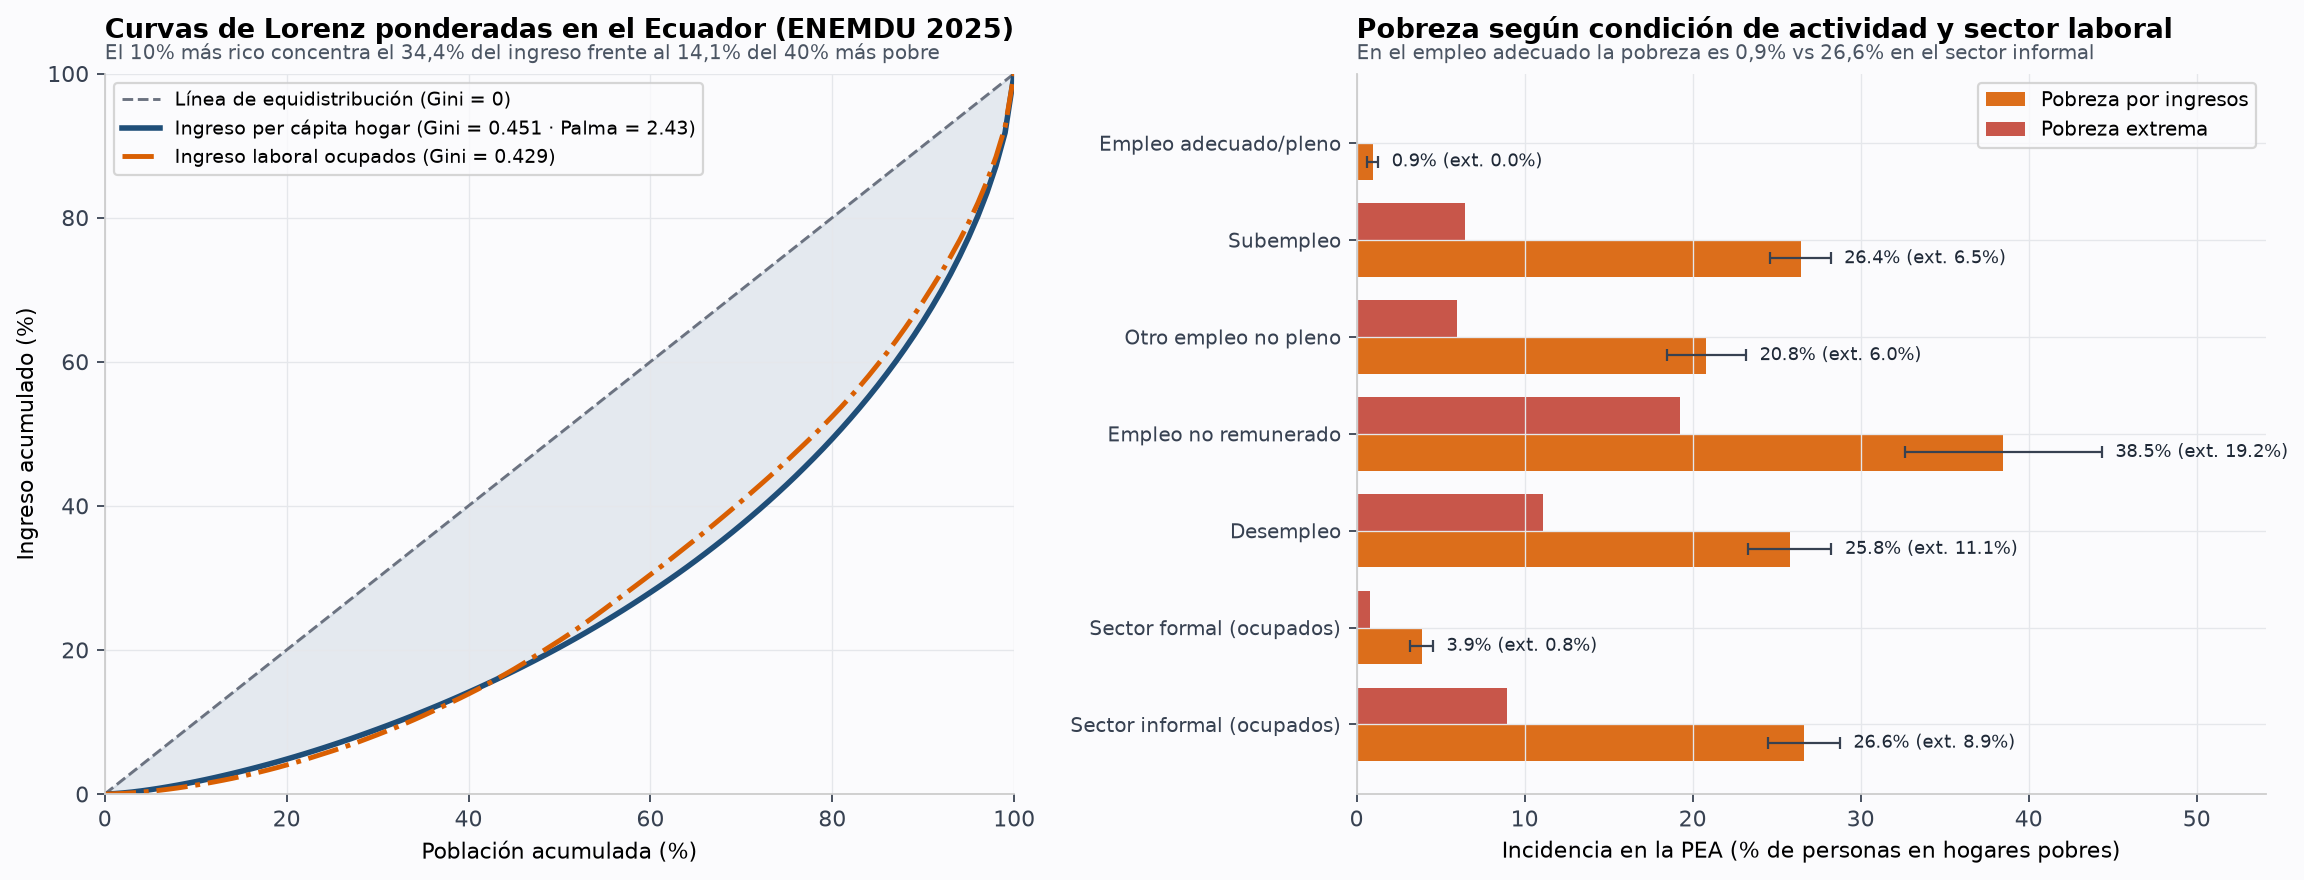

In [4]:
import tempfile
from pathlib import Path
from IPython.display import Image, display
from empleo_enemdu import graficos

# Las figuras se regeneran aquí desde los datos (en una carpeta temporal) y se muestran en línea
DIR_TMP = Path(tempfile.mkdtemp())

display(Image(filename=graficos.fig_10_curva_lorenz_y_pobreza_laboral(desig, DIR_TMP)))